# TodoBarato AI · EP3 ITY1102 · Entrenamiento en Colab e inferencia con contrato SageMaker

**Arquitectura de Sistemas de Inteligencia Artificial · Equipo 1:** Nicolás Estefanía, Diego Tapia y Ariel Espinoza

Por indicación del docente, la plataforma gestionada de **entrenamiento** es **Google Colab** en lugar de SageMaker: en
la cuenta de AWS Academy del equipo, `sagemaker:CreateModel`, `CreateEndpoint` e `iam:PassRole` están denegados
(`EP3_ITY1102/evidencia/sagemaker-intento.txt`). El modelo se sirve con el **mismo contrato de SageMaker**
(`GET /ping`, `POST /invocations`, artefacto `model.tar.gz`) en un contenedor sobre EC2 con Auto Scaling.

| Paso | Qué hace | Indicador |
|---|---|---|
| 1 | Prepara el entorno (en Colab clona el repositorio) | — |
| 2 | Carga el dataset: 60 productos reales de Paris → 554 pares etiquetados | IE1, IE5 |
| 3 | Entrena 3 modelos con búsqueda en malla y validación cruzada agrupada; elige por F1 | IE1 |
| 4 | Métricas de prueba: accuracy, precision, recall, F1, ROC AUC y matriz de confusión | IE10 |
| 5 | Exporta `model.tar.gz` y lo sirve con el contrato de SageMaker (`/ping`, `/invocations`) | IE1, IE4 |
| 6 | Consume la API REST desplegada en AWS: entrada → procesamiento → modelo → resultado | IE2, IE7, IE9 |


## 1. Entorno

In [1]:
import os, sys, subprocess, pathlib, time, json

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAMA = "master"
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", RAMA, "https://github.com/niKo-ing/PROYECTOENGINEER-AI.git", "proyecto"], check=True)
    os.chdir("proyecto")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn>=1.5,<2", "fastapi>=0.115,<1", "uvicorn>=0.30,<1"], check=True)
else:  # ejecución local: subir hasta la raíz del repositorio
    raiz = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "ml" / "train.py").exists())
    os.chdir(raiz)

import numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt
print("Python", sys.version.split()[0], "· scikit-learn", sklearn.__version__, "· Colab" if EN_COLAB else "· local")

Python 3.12.13 · scikit-learn 1.9.1 · local


## 2. Datos

`productos.csv` es la exportación de los **60 productos reales** que se ingestaron de Paris con los conectores del
proyecto (notebooks, celulares y accesorios). A partir de ellos `ml/dataset.py` genera pares etiquetados:

* **positivo:** el mismo título reescrito como lo haría otra tienda (sin marca, otro orden, abreviaturas, erratas, datos que faltan);
* **negativo difícil:** misma marca con otro modelo, otra capacidad/RAM u otro color;
* **negativo fácil:** productos al azar.

La partición es **por producto**: ningún producto aparece en entrenamiento y prueba a la vez.

In [2]:
from ml.dataset import build_pairs, split_by_product
from ml.train import SEED, load_products_csv

productos = load_products_csv(pathlib.Path("EP3_ITY1102/modelo/productos.csv"))
pares = build_pairs(productos, seed=SEED)
entrenamiento, prueba = split_by_product(pares, seed=SEED)
print(f"{len(productos)} productos · {len(pares)} pares · {len(entrenamiento)} entrenamiento · {len(prueba)} prueba")
pd.DataFrame([{"tipo": p.kind, "conjunto": c} for c, ps in (("entrenamiento", entrenamiento), ("prueba", prueba)) for p in ps]) \
  .value_counts().unstack(fill_value=0)

60 productos · 554 pares · 374 entrenamiento · 97 prueba


conjunto,entrenamiento,prueba
tipo,,
positivo,180,60
negativo_variante,41,15
negativo_color,20,5
negativo_marca,67,9
negativo_azar,66,8


In [3]:
pd.set_option("display.max_colwidth", 70)
pd.DataFrame([{"título A": p.a, "título B": p.b, "¿mismo?": p.label, "tipo": p.kind} for p in prueba[:6]])

,título A,título B,¿mismo?,tipo
0,Notebook Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 16G...,Notebok Gamer Nitro ANV15 V15 51Z7 Intel Core RTX 3050 RAM SSD 15 ...,1,positivo
1,Notebook Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 16G...,full nb Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 RAM ...,1,positivo
2,Notebook Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 16G...,pack nb Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 16GB...,1,positivo
3,Notebook Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 16G...,pack nb Gamer Nitro V15 52 ANV15 51Z7 1 Intel Core 5 RTX 3050 16GB...,1,positivo
4,Notebook Gamer Nitro V15 ANV15 52 51Z7 1 Intel Core 5 RTX 3050 16G...,garantia oficial Notebook Gamer Nitro V15 ANV15 52 51Z7 1 Intel Co...,0,negativo_variante
5,Notebook Gamer LOQ AMD Ryzen 7-7735HS 16GB RAM 512GB SSD RTX4050 6...,Gamer LOQ AMD Ryzen 7-7735HS 16GB RAM 512GB SSD RTX4050 6GB 15.6''...,1,positivo


## 3. Entrenamiento

`ml/train.py` compara regresión logística, Random Forest y Gradient Boosting con **búsqueda en malla** y
**validación cruzada agrupada por producto** (5 pliegues, métrica F1), con semilla fija. Elige el mejor y lo evalúa
en el conjunto de prueba, que no vio durante el entrenamiento.

In [4]:
inicio = time.time()
salida = subprocess.run([sys.executable, "-m", "ml.train", "--productos", "EP3_ITY1102/modelo/productos.csv", "--out", "modelo_colab"],
                        check=True, capture_output=True, text=True)
print(f"Entrenamiento: {time.time() - inicio:.0f} s")
m = json.loads(pathlib.Path("modelo_colab/metrics.json").read_text())
pd.DataFrame([{"modelo": k, "mejores hiperparámetros": v["mejores_hiperparametros"], "F1 (validación cruzada)": v["f1_validacion_cruzada"], "segundos": v["segundos"]}
              for k, v in m["candidatos"].items()])

Entrenamiento: 8 s


,modelo,mejores hiperparámetros,F1 (validación cruzada),segundos
0,logistic_regression,{'C': 10.0},0.9009,2.6
1,random_forest,"{'max_depth': 12, 'n_estimators': 100}",0.9104,1.9
2,gradient_boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}",0.9082,1.3


In [5]:
publicado = json.loads(pathlib.Path("EP3_ITY1102/modelo/metrics.json").read_text())
iguales = all(publicado[k] == m[k] for k in ("prueba", "linea_base", "por_tipo_de_par", "tabla_de_umbrales", "dataset"))
print("Modelo elegido:", m["modelo_elegido"])
print("¿Mismas métricas que el modelo desplegado (EP3_ITY1102/modelo/metrics.json)?", "sí" if iguales else "NO")

Modelo elegido: random_forest
¿Mismas métricas que el modelo desplegado (EP3_ITY1102/modelo/metrics.json)? sí


## 4. Métricas en el conjunto de prueba

In [6]:
t, b = m["prueba"], m["linea_base"]
cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
pd.DataFrame([{"": f"Modelo ({m['modelo_elegido']})", **{c: t[c] for c in cols}},
              {"": f"Línea base ({b['regla']})", **{c: b[c] for c in cols}}]).set_index("")

,accuracy,precision,recall,f1,roc_auc
,,,,,
Modelo (random_forest),0.8866,0.9153,0.90,0.9076,0.9309
Línea base (similitud_de_caracteres >= 0.65),0.7629,0.7403,0.95,0.8321,0.8291


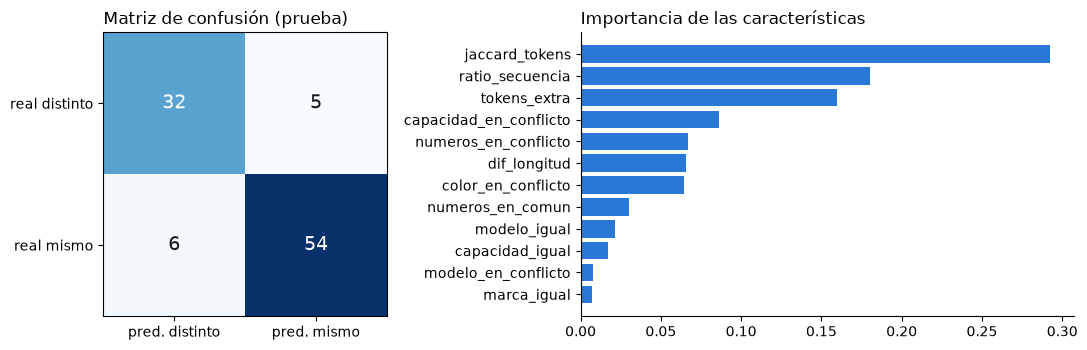

In [7]:
c = t["confusion"]
matriz = np.array([[c["tn"], c["fp"]], [c["fn"], c["tp"]]])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax1.imshow(matriz, cmap="Blues")
for (i, j), v in np.ndenumerate(matriz):
    ax1.text(j, i, v, ha="center", va="center", fontsize=14, color="white" if v > matriz.max() / 2 else "#15171c")
ax1.set_xticks([0, 1], ["pred. distinto", "pred. mismo"]); ax1.set_yticks([0, 1], ["real distinto", "real mismo"])
ax1.set_title("Matriz de confusión (prueba)", loc="left")
imp = pd.Series(m["importancia_caracteristicas"]).sort_values()
ax2.barh(imp.index, imp.values, color="#2a78d6")
ax2.set_title("Importancia de las características", loc="left"); ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [8]:
from IPython.display import display

display(pd.DataFrame(m["tabla_de_umbrales"]).set_index("umbral").rename(columns={"cobertura_de_positivos": "cobertura de positivos"}))
display(pd.DataFrame(m["por_tipo_de_par"]).T.rename_axis("tipo de par").rename(columns={"n": "pares"}))

,precision,cobertura de positivos
umbral,,
0.5,0.915,0.900
0.6,0.945,0.867
0.7,0.942,0.817
0.8,0.953,0.683
0.9,0.972,0.583


,pares,aciertos
tipo de par,,
negativo_azar,8.0,1.0000
negativo_color,5.0,1.0000
negativo_marca,9.0,1.0000
negativo_variante,15.0,0.6667
positivo,60.0,0.9000


**Lectura.** El modelo supera a la línea base en precisión y F1. La línea base tiene más recall, pero a costa de
falsos positivos: mezclar productos distintos es el error más caro para comparar precios. El punto débil son las
variantes cuando una tienda omite la capacidad. Por eso el umbral de `match` es 0,70 (precisión ≈ 0,94) y entre 0,35 y
0,70 la decisión es `ambiguous`, que queda para revisión.

## 5. Artefacto e inferencia con el contrato de SageMaker

SageMaker espera un `model.tar.gz` que descomprime en `/opt/ml/model`, y un contenedor que responde `GET /ping` y
`POST /invocations` en el puerto 8080. `ml/serve.py` cumple ese contrato; es el mismo servidor que corre en EC2.

In [9]:
import hashlib, tarfile

with tarfile.open("modelo_colab/model.tar.gz", "w:gz") as tar:
    tar.add("modelo_colab/match_model.joblib", arcname="match_model.joblib")
datos = pathlib.Path("modelo_colab/model.tar.gz").read_bytes()
print(f"model.tar.gz: {len(datos) / 1024:.0f} KB · sha256 {hashlib.sha256(datos).hexdigest()[:16]}…")

model.tar.gz: 106 KB · sha256 3802e2fd24e40839…


In [10]:
import requests

entorno = {**os.environ, "MATCH_MODEL_PATH": "modelo_colab/match_model.joblib"}
servidor = subprocess.Popen([sys.executable, "-m", "uvicorn", "ml.serve:app", "--port", "8080", "--log-level", "warning"], env=entorno)
for _ in range(60):
    try:
        print("GET /ping →", requests.get("http://127.0.0.1:8080/ping", timeout=1).json()); break
    except requests.RequestException:
        time.sleep(0.5)

ejemplos = [("Samsung Galaxy A54 128GB Negro", "Celular Galaxy A54 5G 128 GB Negro"),
            ("Apple iPhone 13 128GB Negro", "Apple iPhone 13 256GB Negro"),
            ("Xiaomi Redmi Note 15 Pro 256GB Azul", "Xiaomi Redmi Note 15 Pro 256GB Verde"),
            ("Notebook Lenovo IdeaPad 3 Ryzen 5 8GB 512GB", "Audífonos JBL Tune 520BT Negro")]
r = requests.post("http://127.0.0.1:8080/invocations", json={"pairs": [{"a": a, "b": b} for a, b in ejemplos]}, timeout=5).json()
pd.DataFrame([{"título A": a, "título B": b, "decisión": p["decision"], "P(mismo)": p["probability"], "razones": "; ".join(p["reasons"])}
              for (a, b), p in zip(ejemplos, r["predictions"])])

GET /ping → {'status': 'ok', 'model_version': '20261125', 'uptime_s': 2}


,título A,título B,decisión,P(mismo),razones
0,Samsung Galaxy A54 128GB Negro,Celular Galaxy A54 5G 128 GB Negro,match,0.751,misma capacidad de almacenamiento/memoria; comparten el código de ...
1,Apple iPhone 13 128GB Negro,Apple iPhone 13 256GB Negro,no_match,0.180,las capacidades (GB/TB) son distintas: es otra variante; misma mar...
2,Xiaomi Redmi Note 15 Pro 256GB Azul,Xiaomi Redmi Note 15 Pro 256GB Verde,no_match,0.330,misma capacidad de almacenamiento/memoria; misma marca; títulos mu...
3,Notebook Lenovo IdeaPad 3 Ryzen 5 8GB 512GB,Audífonos JBL Tune 520BT Negro,no_match,0.000,títulos muy distintos (similitud 0.22)


In [11]:
def medir(n_pares, repeticiones):
    cuerpo = {"pairs": [{"a": a, "b": b} for a, b in (ejemplos * 16)[:n_pares]]}
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter(); requests.post("http://127.0.0.1:8080/invocations", json=cuerpo, timeout=5); tiempos.append((time.perf_counter() - inicio) * 1000)
    return {"pares por llamada": n_pares, "p50 ms": round(np.percentile(tiempos, 50), 1), "p95 ms": round(np.percentile(tiempos, 95), 1),
            "ms por par (p50)": round(np.percentile(tiempos, 50) / n_pares, 2)}

latencias = pd.DataFrame([medir(1, 100), medir(64, 50)]).set_index("pares por llamada")
servidor.terminate()
latencias

,p50 ms,p95 ms,ms por par (p50)
pares por llamada,,,
1,7.2,8.3,7.22
64,14.0,15.3,0.22


## 6. Consumo de la API REST desplegada en AWS

La API (`/api/v1/ml/*`) corre detrás de CloudFront (HTTPS) y un balanceador con Auto Scaling. Para ejecutar esta
sección, guarde en **Colab → Secretos** `TODOBARATO_API_URL` (la URL que imprime `desplegar_asg.sh` o
`desplegar.sh`) y `TODOBARATO_API_KEY`.

In [12]:
def secreto(nombre):
    try:
        from google.colab import userdata
        return userdata.get(nombre)
    except Exception:
        return os.environ.get(nombre)

API_URL, API_KEY = (secreto("TODOBARATO_API_URL") or "").rstrip("/"), secreto("TODOBARATO_API_KEY") or ""
if not API_URL:
    print("Sin TODOBARATO_API_URL: despliegue con EP3_ITY1102/infra/desplegar_asg.sh y vuelva a ejecutar esta celda.")
else:
    ml = f"{API_URL}/api/v1/ml"
    llave = {"x-api-key": API_KEY}
    print("GET /health →", requests.get(f"{ml}/health", timeout=10).json())
    print("POST /match sin llave →", requests.post(f"{ml}/match", json={"a": "x", "b": "y"}, timeout=10).status_code, "(se espera 401)")
    print("POST /match entrada inválida →", requests.post(f"{ml}/match", json={"a": "x"}, headers=llave, timeout=10).status_code, "(se espera 422)")
    for a, b in ejemplos[:2]:
        print(f"POST /match «{a}» vs «{b}» →", requests.post(f"{ml}/match", json={"a": a, "b": b}, headers=llave, timeout=10).json())
    print("POST /match/async →", requests.post(f"{ml}/match/async", json={"a": ejemplos[2][0], "b": ejemplos[2][1]}, headers=llave, timeout=10).json())
    time.sleep(3)
    print("GET /decisions →", json.dumps(requests.get(f"{ml}/decisions?limit=1", headers=llave, timeout=10).json(), ensure_ascii=False)[:400])
    tiempos = []
    for _ in range(30):
        inicio = time.perf_counter(); requests.post(f"{ml}/match", json={"a": ejemplos[0][0], "b": ejemplos[0][1]}, headers=llave, timeout=10)
        tiempos.append((time.perf_counter() - inicio) * 1000)
    print(f"Latencia desde este notebook (30 llamadas): p50 {np.percentile(tiempos, 50):.0f} ms · p95 {np.percentile(tiempos, 95):.0f} ms · p99 {np.percentile(tiempos, 99):.0f} ms")

Sin TODOBARATO_API_URL: despliegue con EP3_ITY1102/infra/desplegar_asg.sh y vuelva a ejecutar esta celda.


## Resumen

* **Entrenamiento gestionado (Colab):** dataset, búsqueda de hiperparámetros, métricas y artefacto, reproducibles con
  la semilla fija; dan las mismas métricas que el modelo desplegado.
* **Inferencia:** el mismo `model.tar.gz` y el mismo contrato de SageMaker (`/ping`, `/invocations`), servido en EC2 con
  Auto Scaling (2 → 4 réplicas medidas) porque el laboratorio no permite crear endpoints de SageMaker.
* **Consumo:** API REST con llave, límite de tasa, validación y TLS en el borde; flujo síncrono y asíncrono (RabbitMQ).
